# TranslateAI Ancient Character Recognition



---

## 📖 TranslateAI — Digitizing History

You have just been hired as a Machine Learning Engineer at **TranslateAI**, a startup working with international museums. Your first task is to build a neural network that can automatically classify ancient Japanese cursive texts.

We will use the **KMNIST** dataset — 28x28 grayscale images of 10 cursive characters: *o, ki, su, tsu, na, ha, ma, ya, re, wo*.

To ensure top performance, you must optimize your deep learning pipeline using **Batch Normalization** and **Advanced Optimizers (Adam)**.

---

## : Load, Explore, & Preprocess Data

### 1.1 Download the Dataset

We will use `torchvision.datasets.KMNIST` to download the dataset.



In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Class names for KMNIST
class_names = ['o', 'ki', 'su', 'tsu', 'na', 'ha', 'ma', 'ya', 're', 'wo']

# Download KMNIST
full_train_dataset = torchvision.datasets.KMNIST(root='./data', train=True, download=True)
test_dataset_raw = torchvision.datasets.KMNIST(root='./data', train=False, download=True)

print(f"Training set size: {len(full_train_dataset)}")
print(f"Test set size: {len(test_dataset_raw)}")

Training set size: 60000
Test set size: 10000


### 1.2 Visualize Sample Grayscale Images

Create a **2x5 subplot figure** (figsize 12x5) showing one sample image from **each of the 10 classes**.
- Title each subplot with its class name
- Turn off axis ticks
- Ensure you use `cmap='gray'` for visualization.

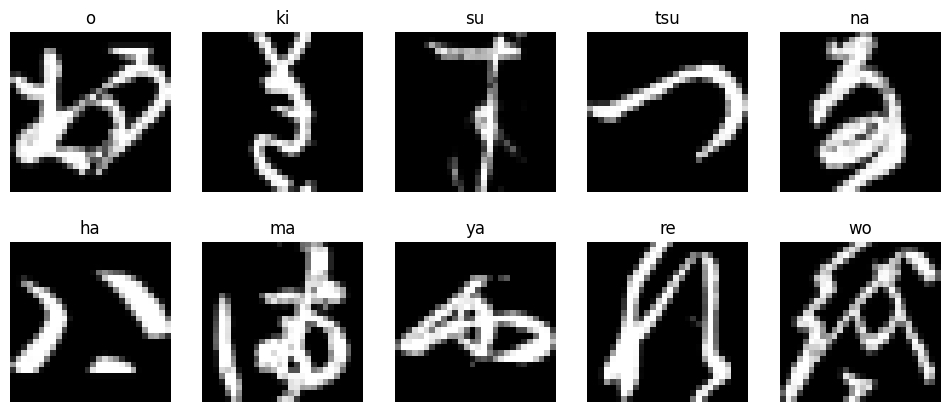

In [ ]:

train_images_all = full_train_dataset.data.numpy()
train_labels_all = full_train_dataset.targets.numpy()
test_images_all = test_dataset_raw.data.numpy()
test_labels_all = test_dataset_raw.targets.numpy()

fig, axes = plt.subplots(2,5, figsize=(12,5))
axes = axes.flatten()
for i, label in enumerate(class_names):
  index = np.where(train_labels_all == i )
  id_values = index[0][0]
  axes[i].imshow(train_images_all[id_values], cmap='gray')
  axes[i].set_title(f'{label}')
  axes[i].axis('off')
plt.show()

### 1.3 Data Scaling & Splitting

**Your tasks:**
1. Extract images and labels from both train and test datasets as NumPy arrays. (Note: KMNIST images are 28x28)
2. Normalize the pixel values to the range [0, 1] by MinMax Scaling.
3. Split the training data into **train (50,000)** and **validation (10,000)** using `train_test_split` with `random_state=42`.
4. Convert all sets to PyTorch tensors — images as `float32`, labels as `long`.

**Required variables:** `X_train, X_val, X_test` (float32 tensors), `y_train, y_val, y_test` (long tensors)

In [ ]:

from sklearn.model_selection import train_test_split

X_train_np, X_val_np, y_train_np, y_val_np = train_test_split(train_images_all, train_labels_all, test_size=1/6, random_state=42)
X_train = torch.tensor(X_train_np, dtype=torch.float32) / 255.0
y_train = torch.tensor(y_train_np, dtype=torch.long)

X_val = torch.tensor(X_val_np, dtype=torch.float32) / 255.0
y_val = torch.tensor(y_val_np, dtype=torch.long)

X_test = torch.tensor(test_images_all, dtype=torch.float32) / 255.0
y_test = torch.tensor(test_labels_all, dtype=torch.long)

In [ ]:
# --- TEST CELL (DO NOT MODIFY) ---
assert X_train.shape == (50000, 28, 28), f"Expected (50000, 28, 28), got {X_train.shape}"
assert X_val.shape == (10000, 28, 28)
assert X_train.dtype == torch.float32
assert y_train.dtype == torch.long
print("✅ Q1.3 Passed!")

✅ Q1.3 Passed!


---

## Build PyTorch DataLoaders

Create `TensorDataset` and `DataLoader` objects for train, validation, and test sets.

- **batch_size = 256**
- **shuffle = True** for training, **False** for validation and test

**Required variables:** `train_loader`, `val_loader`, `test_loader`

In [ ]:

trainDS = TensorDataset(X_train, y_train)
validationDS = TensorDataset(X_val, y_val)
testDS = TensorDataset(X_test, y_test)

train_loader = DataLoader(trainDS, batch_size=256, shuffle=True)
val_loader = DataLoader(validationDS, batch_size=256, shuffle=False)
test_loader = DataLoader(testDS, batch_size=256, shuffle=False)


In [ ]:
# --- TEST CELL (DO NOT MODIFY) ---
batch_X, batch_y = next(iter(train_loader))
assert batch_X.shape == (256, 28, 28)
assert batch_y.dtype == torch.long
print("✅ Q2 Passed!")

✅ Q2 Passed!


---

## Deep Neural Network Architecture

Create a class `TranslateAIClassifier` inheriting from `nn.Module`.

Use `nn.Sequential` with this architecture. Since the input is `28x28`, the flattened size is **784**.

| Layer | Description |
|-------|-------------|
| Flatten | Convert 28x28 → 784 |
| Linear | 784 → 512 |
| BatchNorm1d | Batch Normalization (512 features) |
| ReLU | Activation |
| Linear | 512 → 256 |
| BatchNorm1d | Batch Normalization (256 features) |
| ReLU | Activation |
| Linear | 256 → 128 |
| BatchNorm1d | Batch Normalization (128 features) |
| ReLU | Activation |
| Linear | 128 → 10 |

After defining the class, create an instance called `model` and print it.

In [ ]:

class TranslateAIClassifier(nn.Module):
  def __init__(self, input_size, num_classes):
    super().__init__()

    self.network = nn.Sequential(
        nn.Flatten(),
        nn.Linear(input_size, 512),
        nn.BatchNorm1d(512),
        nn.ReLU(),
        nn.Linear(512, 256),
        nn.BatchNorm1d(256),
        nn.ReLU(),
        nn.Linear(256, 128),
        nn.BatchNorm1d(128),
        nn.ReLU(),
        nn.Linear(128, num_classes)

    )
  def forward(self, features):
      output = self.network(features)
      return output
model = TranslateAIClassifier(input_size=784, num_classes=10)
print(model)

TranslateAIClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=128, bias=True)
    (8): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:
# --- TEST CELL (DO NOT MODIFY) ---
test_input = torch.randn(5, 28, 28)
test_output = model(test_input)
assert test_output.shape == (5, 10)
has_batchnorm = any(isinstance(m, nn.BatchNorm1d) for m in model.modules())
assert has_batchnorm, "Model must include BatchNorm1d layers"
print("✅ Q3 Passed!")

✅ Q3 Passed!


---

## Advanced Training Pipeline

### 4.1 Setup Optimizer and Loss (5 Marks)
- Loss function: `nn.CrossEntropyLoss`
- Optimizer: `optim.Adam` with `lr=0.001`
- Number of epochs: **15**

In [ ]:

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
epochs = 15

### 4.2 PyTorch Training Pipeline

Write the training loop for **15 epochs**.

For each epoch:
1. Set model to training mode (`model.train()`)
2. Train on `train_loader` (forward pass, calculate loss, backward pass, optimizer step)
3. Set model to evaluation mode (`model.eval()`)
4. Evaluate on `val_loader` and compute validation loss and accuracy.
5. Print: `Epoch {epoch+1}/{epochs} | Train Loss: {:.4f} | Val Loss: {:.4f}`

Store: `train_losses`, `val_losses` lists.

In [ ]:

train_losses = []
val_losses =[]
train_accuracies =[]
val_accuracies = []

for epoch in range(epochs):
  train_loss = 0.0
  correctTr = 0.0
  totalTr = 0.0
  model.train()
  for i, labels in train_loader:
    optimizer.zero_grad()
    outputs = model(i)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    train_loss += loss.item()
    pred = outputs.argmax(dim=1)
    correctTr += (pred==labels).sum().item()
    totalTr += labels.shape[0]

  val_loss = 0.0
  correctVal = 0.0
  totalVal = 0.0
  model.eval()
  with torch.no_grad():
    for i, labels in val_loader:
      outputs = model(i)
      loss = criterion(outputs, labels)
      val_loss += loss.item()
      pred = outputs.argmax(dim=1)
      correctVal +=(pred==labels).sum().item()
      totalVal +=labels.shape[0]

  train_losses.append(train_loss/ len(train_loader))
  val_losses.append(val_loss/ len(val_loader))

  train_accuracies.append(correctTr/ totalTr)
  val_accuracies.append(correctVal/totalVal)
  print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss/len(val_loader):.4f}")

Epoch 1/15 | Train Loss: 0.3812 | Val Loss: 0.1954
Epoch 2/15 | Train Loss: 0.1342 | Val Loss: 0.1530
Epoch 3/15 | Train Loss: 0.0826 | Val Loss: 0.1465
Epoch 4/15 | Train Loss: 0.0534 | Val Loss: 0.1465
Epoch 5/15 | Train Loss: 0.0425 | Val Loss: 0.1347
Epoch 6/15 | Train Loss: 0.0315 | Val Loss: 0.1607
Epoch 7/15 | Train Loss: 0.0250 | Val Loss: 0.1390
Epoch 8/15 | Train Loss: 0.0228 | Val Loss: 0.1433
Epoch 9/15 | Train Loss: 0.0213 | Val Loss: 0.1549
Epoch 10/15 | Train Loss: 0.0263 | Val Loss: 0.1508
Epoch 11/15 | Train Loss: 0.0227 | Val Loss: 0.1468
Epoch 12/15 | Train Loss: 0.0152 | Val Loss: 0.1474
Epoch 13/15 | Train Loss: 0.0173 | Val Loss: 0.1378
Epoch 14/15 | Train Loss: 0.0150 | Val Loss: 0.1702
Epoch 15/15 | Train Loss: 0.0202 | Val Loss: 0.1430


In [ ]:
# --- TEST CELL (DO NOT MODIFY) ---
assert len(train_losses) == 15, f"Expected 15 epochs, got {len(train_losses)}"
assert len(val_losses) == 15
print("✅ Q4.2 Passed!")

✅ Q4.2 Passed!


---

## Evaluation & Analytics

### 5.1 Test Evaluation
Evaluate the model on the **test set**.
- Print the Test Accuracy.
- Collect Test dataset's all predictions into a list called `all_preds`.

In [ ]:

correctTest = 0.0
totalTest = 0.0
all_preds = []
all_labels = []
model.eval()
with torch.no_grad():
  for i,labels in test_loader:
    outputs = model(i)
    pred = outputs.argmax(dim=1)
    for p in pred:
      all_preds.append(p)
    for l in labels:
      all_labels.append(l)
    correctTest += (pred== labels).sum().item()
    totalTest += labels.shape[0]
test_accuracy = (correctTest/ totalTest)*100
print(f'Test Accuracy {test_accuracy}')

Test Accuracy 90.64


### 5.2 Plot Learning Curves
Plot **Training Loss** and **Validation Loss** on the same figure across epochs. Include a legend and title.

Text(0, 0.5, 'Loss')

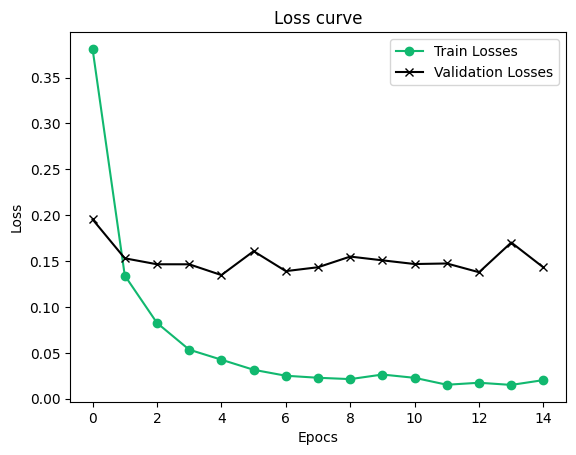

In [ ]:

plt.plot(train_losses, label= 'Train Losses', color = '#11b86f',marker='o')
plt.plot(val_losses, label='Validation Losses', color='black', marker='x')
plt.legend()
plt.title("Loss curve")
plt.xlabel("Epocs")
plt.ylabel('Loss')

### 5.3 Confusion Matrix & Analysis
1. Plot the confusion matrix using `ConfusionMatrixDisplay`.
2. Write a brief markdown explanation of which ancient character classes are most frequently confused by the model based on the matrix.

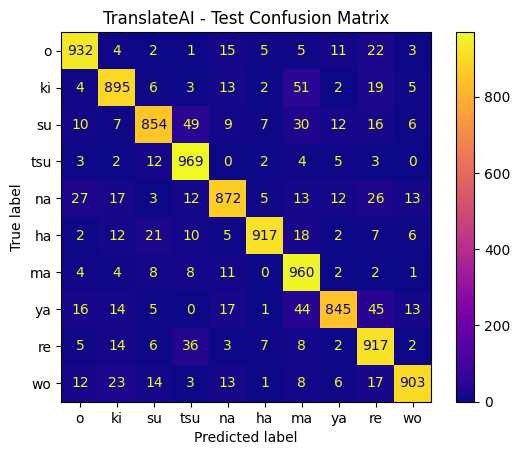

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# YOUR CODE HERE
cnfm = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(all_labels, all_preds), display_labels=class_names)
cnfm.plot(cmap='plasma', values_format='d')
plt.title("TranslateAI - Test Confusion Matrix")
plt.show()

*Double-click here to write your analysis*

**Your Analysis:**
2. Based on the matrix, 49+12=61 were missclassified between su<->tsu, it was the highest, followed by ma<->ki with 51+4=55 missclassification.
